## Formal introduction to DataFrames

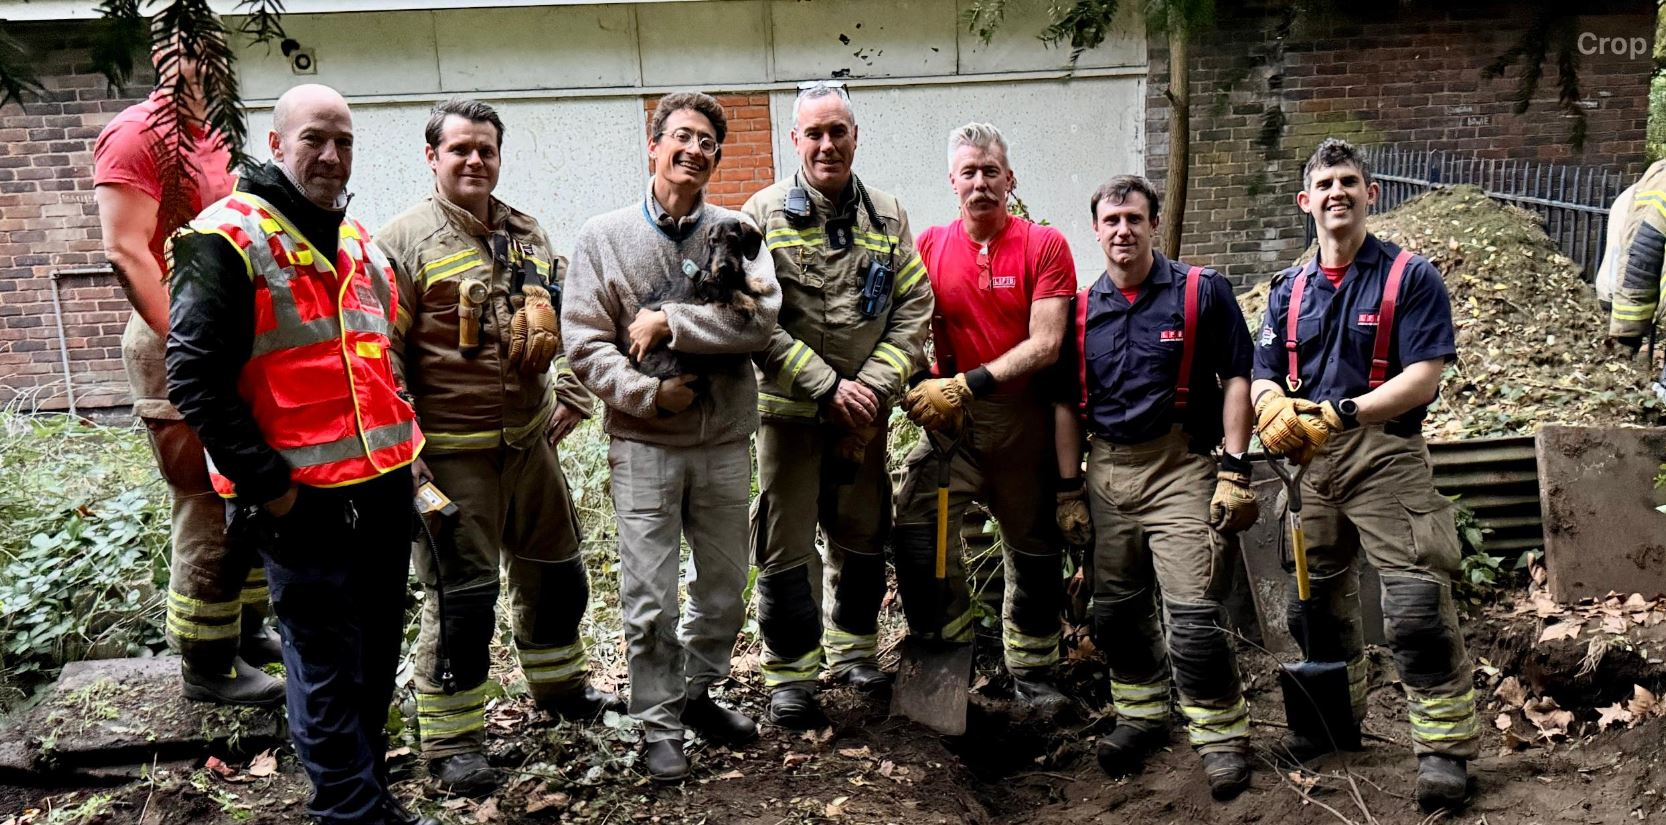

**0. The basics**

For homework, we took a deeper look into pandas, the Python Data Analysis Library. As we have seen, it contains an extremely powerful object called a DataFrame, designed to work with **tabular data.** Think about a Python implementation of a spreadsheet. Each row of the data frame refers to a different "unit of observation" and each column refers to a particular measurement or attribute of a unit.

**The London Fire Brigade**

<img src="images/lfb.png" width=500>

We have been using data collected by the London Fire Brigade. From [their website](https://data.london.gov.uk/dataset/animal-rescue-incidents-attended-by-lfb-2ogkn)...

The file has one row per incident (per rescue), and the columns describe aspects of what happened, the brigade resources involved, a time and a location.

**Loading the data**

If you didn't do this with your homework, you'll need to "install the app" `openpyxl` so that you can read the Excel file the brigade has made available.

In [1]:
# Execute this install instruction (shift-return)

%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

# the string "url" contains the link from the LFB site.
url = "https://data.london.gov.uk/download/2ogkn/01007433-55c2-4b8a-b799-626d9e3bc284/Animal%20Rescue%20incidents%20attended%20by%20LFB%20from%20Jan%202009.csv.xlsx"

# To read in the data we have to look like someone with a browser and not someone with a Python program.
# So we are going to use a custom "User-Agent" in the header of our request for the file (more on this in class)
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

# the function "read_excel()" takes a few arguments... for example, we can tell Pandas that a column represents dates
lfb = pd.read_excel(url, parse_dates=["DateTimeOfCall"], storage_options=headers)

# recall the data's dimensions...
lfb.shape

(14361, 31)

In [4]:
lfb.columns

Index(['IncidentNumber', 'DateTimeOfCall', 'CalYear', 'FinYear',
       'TypeOfIncident', 'PumpCount', 'PumpHoursTotal',
       'HourlyNotionalCost(£)', 'IncidentNotionalCost(£)', 'FinalDescription',
       'AnimalGroupParent', 'OriginofCall', 'PropertyType', 'PropertyCategory',
       'SpecialServiceTypeCategory', 'SpecialServiceType', 'WardCode', 'Ward',
       'BoroughCode', 'Borough', 'StnGroundName', 'UPRN', 'Street', 'USRN',
       'PostcodeDistrict', 'Easting_m', 'Northing_m', 'Easting_rounded',
       'Northing_rounded', 'Latitude', 'Longitude'],
      dtype='str')

Here is a description of the columns in the `lfb` DataFrame (often called a data dictionairy).

|variable                      |description |
|:-----------------------------|:-----------|
|IncidentNumber                | Unique incident ID |
|DateTimeOfCall                | Day and time of call (day/month/year hour:minute) |
|CalYear                       | Calendar Year |
|FinYear                       | Fiscal year|
|TypeOfIncident                | Type of incident |
|PumpCount                     | Pump count (number of trucks) |
|PumpHoursTotal                | Pump hours total |
|HourlyNotionalCost(£)         | Hourly cost |
|IncidentNotionalCost(£)       | Total cost of incident |
|FinalDescription              | Final description |
|AnimalGroupParent             | Type of animal |
|OriginofCall                  | Where call originated |
|PropertyType                  | Property type |
|PropertyCategory              | Property category |
|SpecialServiceTypeCategory.   | Service type category  |
|SpecialServiceType            | Service type |
|WardCode                      | Ward Code |
|Ward                          | Ward name |
|BoroughCode                   | Borough code |
|Borough                       | Borough name |
|StnGroundName.                | Station name |
|UPRN                          | Unique property reference number |
|Street                        | Street name |
|USRN                          | unique street reference number |
|PostcodeDistrict              | Postal code district |
|Easting_m                     | Easting measure |
|Northing_m                    | Northing measure |
|Easting_rounded               | Easting rounded |
|Northing_rounded              | Northing rounded |
|Latitude                      | Lat|
|Longitude                     | Long |

In [ ]:
# this sets a display option for data frames - usually you see just 10 columns and this way you see them all
pd.set_option("display.max_columns", None)

# have a look at the data
lfb.tail(5)

,IncidentNumber,DateTimeOfCall,CalYear,FinYear,TypeOfIncident,PumpCount,PumpHoursTotal,HourlyNotionalCost(£),IncidentNotionalCost(£),FinalDescription,AnimalGroupParent,OriginofCall,PropertyType,PropertyCategory,SpecialServiceTypeCategory,SpecialServiceType,WardCode,Ward,BoroughCode,Borough,StnGroundName,UPRN,Street,USRN,PostcodeDistrict,Easting_m,Northing_m,Easting_rounded,Northing_rounded,Latitude,Longitude
0,139091,2009-01-01 03:01:00,2009,2008/09,Special Service,1.0,2.0,255,510.0,Redacted,Dog,Person (land line),House - single occupancy,Dwelling,Other animal assistance,Animal assistance involving livestock - Other ...,E05011467,Crystal Palace & Upper Norwood,E09000008,Croydon,Norbury,NaN,Waddington Way,20500146.0,SE19,NaN,NaN,532350,170050,NaN,NaN
1,275091,2009-01-01 08:51:00,2009,2008/09,Special Service,1.0,1.0,255,255.0,Redacted,Fox,Person (land line),Railings,Outdoor Structure,Other animal assistance,Animal assistance involving livestock - Other ...,E05000169,Woodside,E09000008,Croydon,Woodside,NaN,Grasmere Road,NaN,SE25,534785.0,167546.0,534750,167550,51.390954,-0.064167
2,2075091,2009-01-04 10:07:00,2009,2008/09,Special Service,1.0,1.0,255,255.0,Redacted,Dog,Person (mobile),Pipe or drain,Outdoor Structure,Animal rescue from below ground,Animal rescue from below ground - Domestic pet,E05013756,Carshalton Central,E09000029,Sutton,Wallington,NaN,Mill Lane,NaN,SM5,528041.0,164923.0,528050,164950,51.368941,-0.161985
3,2872091,2009-01-05 12:27:00,2009,2008/09,Special Service,1.0,1.0,255,255.0,Redacted,Horse,Person (mobile),"Intensive Farming Sheds (chickens, pigs etc)",Non Residential,Animal rescue from water,Animal rescue from water - Farm animal,E05013568,Harefield Village,E09000017,Hillingdon,Ruislip,1.000215e+11,Park Lane,21401484.0,UB9,504689.0,190685.0,504650,190650,51.605283,-0.489684
4,3553091,2009-01-06 15:23:00,2009,2008/09,Special Service,1.0,1.0,255,255.0,Redacted,Rabbit,Person (mobile),House - single occupancy,Dwelling,Other animal assistance,Animal assistance involving livestock - Other ...,E05013971,Gooshays,E09000016,Havering,Harold Hill,NaN,Swindon Lane,21300122.0,RM3,NaN,NaN,554650,192350,NaN,NaN


We are going to use [Altair](https://altair-viz.github.io/) for making graphics. There are plenty of packages for Python that will do what we want, but Altair works best for me. 

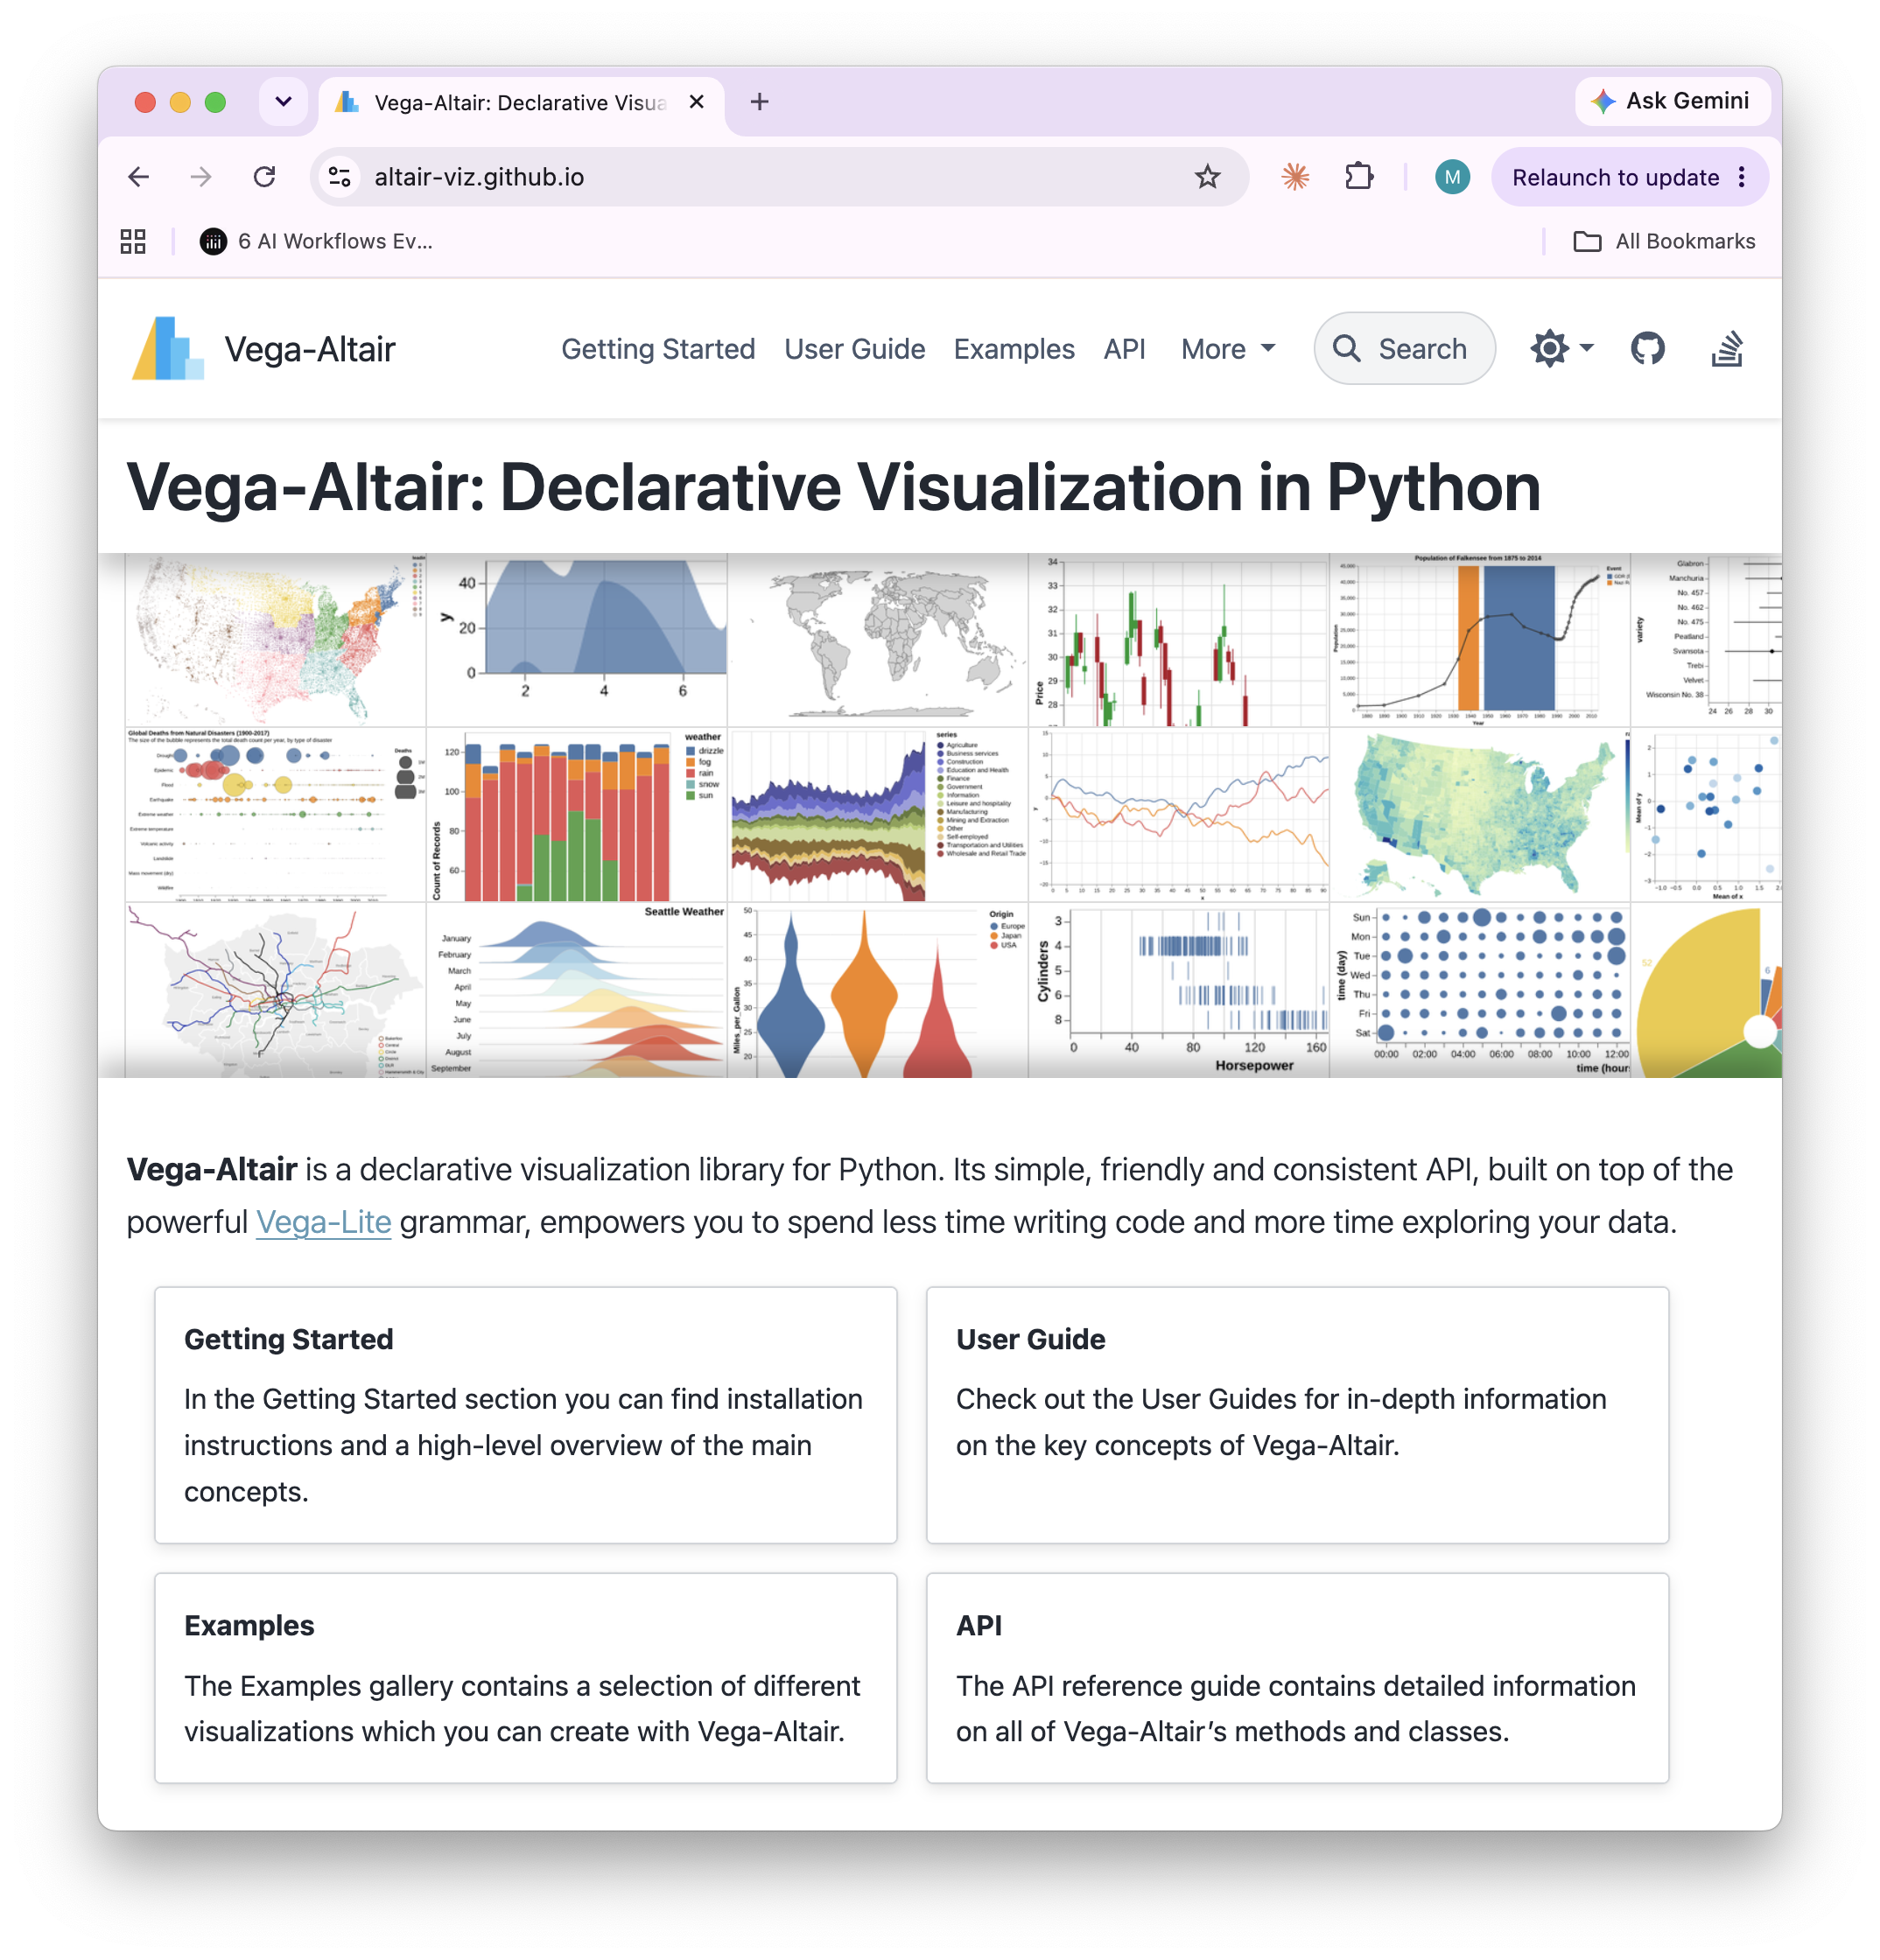

It makes use of basic "marks and encodings" that map features in data to characteristics of a plot. We'll see this later in the lesson.

**1. Warm up**

There are various news stories about animal rescues. [Here's one.](https://www.london-fire.gov.uk/incidents/2025/october/dog-rescue-hackney/). Can we find the rescue in our data?

In [ ]:
# your code here

What about [this story](https://www.theguardian.com/world/2025/nov/02/firefighters-charities-animal-rescue-callouts-england) that includes overall statistics about domestic animals over time? Or [this one](https://www.telegraph.co.uk/news/2024/12/29/firefighters-spend-record-amount-money-rescuing-cats/?ICID=continue_without_subscribing_reg_first&icid=login_test-login_success-password#comment)...

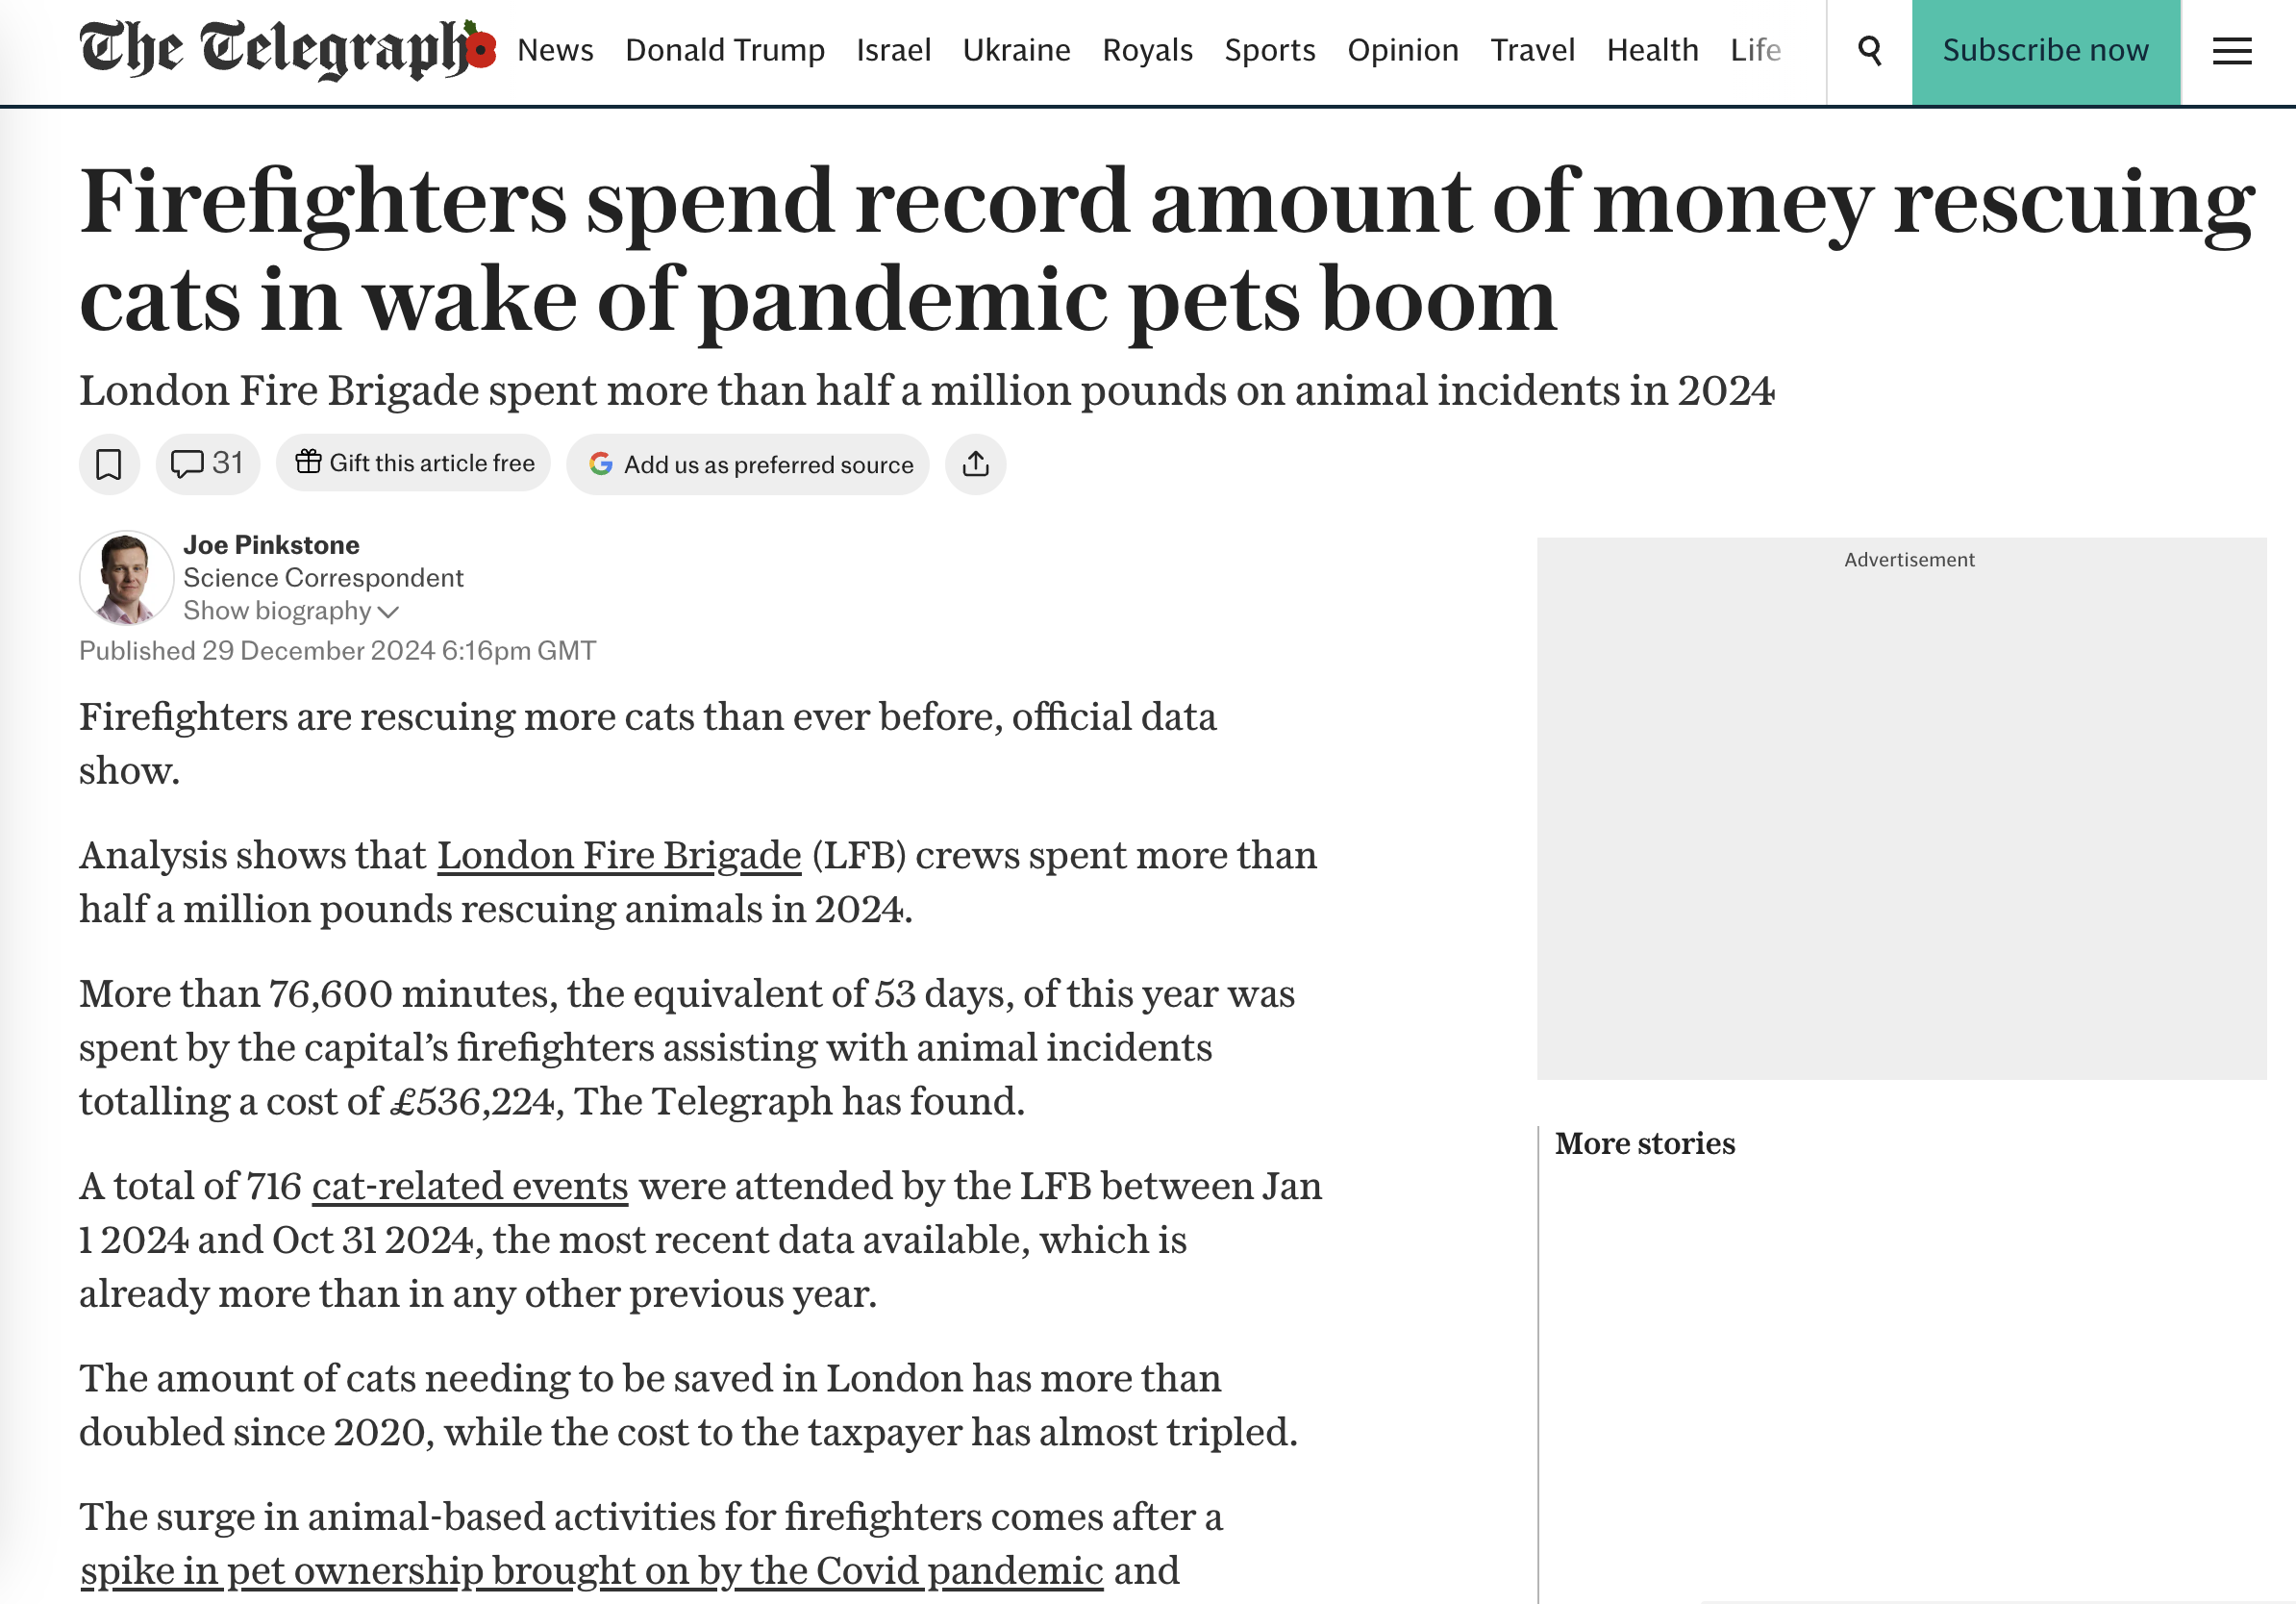

In [34]:
# your code here


**2.** Let's consider the progression of rescues over time. Are they increasing? Decreasing? Come up with a hypothesis you'd like to explore and then map out what you might need to do to evaluate it.

In [19]:
# your code here

Now add dogs. Are the patterns the same? How would you compare them?

In [12]:
lfb.head()

,IncidentNumber,DateTimeOfCall,CalYear,FinYear,TypeOfIncident,PumpCount,PumpHoursTotal,HourlyNotionalCost(£),IncidentNotionalCost(£),FinalDescription,AnimalGroupParent,OriginofCall,PropertyType,PropertyCategory,SpecialServiceTypeCategory,SpecialServiceType,WardCode,Ward,BoroughCode,Borough,StnGroundName,UPRN,Street,USRN,PostcodeDistrict,Easting_m,Northing_m,Easting_rounded,Northing_rounded,Latitude,Longitude
0,139091,2009-01-01 03:01:00,2009,2008/09,Special Service,1.0,2.0,255,510.0,Redacted,Dog,Person (land line),House - single occupancy,Dwelling,Other animal assistance,Animal assistance involving livestock - Other ...,E05011467,Crystal Palace & Upper Norwood,E09000008,Croydon,Norbury,NaN,Waddington Way,20500146.0,SE19,NaN,NaN,532350,170050,NaN,NaN
1,275091,2009-01-01 08:51:00,2009,2008/09,Special Service,1.0,1.0,255,255.0,Redacted,Fox,Person (land line),Railings,Outdoor Structure,Other animal assistance,Animal assistance involving livestock - Other ...,E05000169,Woodside,E09000008,Croydon,Woodside,NaN,Grasmere Road,NaN,SE25,534785.0,167546.0,534750,167550,51.390954,-0.064167
2,2075091,2009-01-04 10:07:00,2009,2008/09,Special Service,1.0,1.0,255,255.0,Redacted,Dog,Person (mobile),Pipe or drain,Outdoor Structure,Animal rescue from below ground,Animal rescue from below ground - Domestic pet,E05013756,Carshalton Central,E09000029,Sutton,Wallington,NaN,Mill Lane,NaN,SM5,528041.0,164923.0,528050,164950,51.368941,-0.161985
3,2872091,2009-01-05 12:27:00,2009,2008/09,Special Service,1.0,1.0,255,255.0,Redacted,Horse,Person (mobile),"Intensive Farming Sheds (chickens, pigs etc)",Non Residential,Animal rescue from water,Animal rescue from water - Farm animal,E05013568,Harefield Village,E09000017,Hillingdon,Ruislip,1.000215e+11,Park Lane,21401484.0,UB9,504689.0,190685.0,504650,190650,51.605283,-0.489684
4,3553091,2009-01-06 15:23:00,2009,2008/09,Special Service,1.0,1.0,255,255.0,Redacted,Rabbit,Person (mobile),House - single occupancy,Dwelling,Other animal assistance,Animal assistance involving livestock - Other ...,E05013971,Gooshays,E09000016,Havering,Harold Hill,NaN,Swindon Lane,21300122.0,RM3,NaN,NaN,554650,192350,NaN,NaN


In [21]:
cats = lfb[lfb["AnimalGroupParent"].str.lower()=="cat"]
cats.groupby("CalYear").size().reset_index(name="Rescues")

,CalYear,Rescues
0,2009,263
1,2010,297
2,2011,309
3,2012,305
4,2013,313
5,2014,298
6,2015,263
7,2016,297
8,2017,258
9,2018,305


**3.** Now consider another variable - Borough. Is there any spatial effect in rescues? What do you think? How might you examine your idea? [Map](https://github.com/radoi90/housequest-data/blob/master/london_boroughs.geojson) out what you need to do.

What about different animals? Do different animals have different spatial distributions? What do you think? How woudl you explore your idea?